## Celda 1. SP-004 — Investigación y experimentación de Filler

### Qué hace esta celda

Presenta el objetivo y el alcance de este laboratorio.

### Por qué la necesitamos

Andro podrá repetir el experimento leyendo el contexto antes de ejecutar código.

### Qué deberíamos observar

El laboratorio estudia Filler como heurística experimental, sin registrarlo en el motor productivo.

## Celda 2. Qué es Filler

### Qué hace esta celda

Describe el ciclo pieza pendiente–fuente activa.

### Por qué la necesitamos

La literatura distingue selección de pieza y colocación geométrica.

### Qué deberíamos observar

Filler agota una fuente buscando cualquier pieza pendiente factible antes de avanzar.

## Celda 3. Qué medimos

### Qué hace esta celda

Resume casos, baselines, métricas y límites del experimento.

### Por qué la necesitamos

La comparación debe conservar fixtures y reglas geométricas del repositorio.

### Qué deberíamos observar

SMALL, MEDIUM y COMPLEX se compararán con FF, BF, WF y Filler.

## Celda 4. Preparación del entorno

### Qué hace esta celda

Añade el backend y la raíz del repositorio al path de Python.

### Por qué la necesitamos

El loader y el motor están en el repositorio local.

### Qué deberíamos observar

Se mostrarán la raíz detectada y la configuración secuencial.

In [1]:
from pathlib import Path  # Importamos Path para buscar archivos del repositorio de forma portable.
import sys  # Importamos sys para que Python encuentre backend y experimentos.
repo_root = Path.cwd()  # Tomamos la carpeta de trabajo como raíz candidata del repositorio.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Comprobamos que Colab esté ubicado dentro de una copia del repositorio.
    repo_root = Path("/content/NewGlass")  # Usamos la ruta convencional si el repositorio fue clonado en Colab.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Evitamos continuar con un path que no tiene los fixtures.
    raise RuntimeError("Clona NewGlass en /content/NewGlass o ejecuta el notebook desde la raíz del repositorio.")  # Explicamos cómo preparar el entorno.
sys.path.insert(0, str(repo_root / "backend"))  # Permitimos imports del paquete app usado por el motor.
sys.path.insert(0, str(repo_root))  # Permitimos importar el loader experimental versionado.
print(f"Repositorio: {repo_root}")  # Confirmamos la ubicación real del código.
print("Ejecución: secuencial; una corrida a la vez")  # Confirmamos la política de recursos del Spike.

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Ejecución: secuencial; una corrida a la vez


### Interpretación de la salida

La ruta detectada debe contener el loader experimental; no se altera ningún archivo productivo.

## Celda 5. Validar fixtures

### Qué hace esta celda

Comprueba los tres JSON oficiales y sus parámetros explícitos.

### Por qué la necesitamos

La comparación solo es válida si ambas políticas reciben exactamente los mismos casos.

### Qué deberíamos observar

Cada fixture se valida contra la lista permitida por el loader.

In [2]:
from experiments.optimization.loader import CASES, read_case  # Reutilizamos el loader y la lista cerrada de casos.
fixture_summary = {}  # Creamos el resumen que usaremos en las explicaciones posteriores.
for case_id in CASES:  # Recorremos SMALL, MEDIUM y COMPLEX en orden fijo.
    data = read_case(case_id)  # Leemos una copia de solo lectura del JSON congelado.
    fixture_summary[case_id] = {"pieces": len(data["pieces"]), "stock": len(data["stock"]), "config": data["config"]}  # Conservamos conteos y configuración.
    print(case_id, fixture_summary[case_id])  # Mostramos la evidencia cargada directamente del fixture.

EXP-SMALL-001 {'pieces': 1, 'stock': 2, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 0, 'separation_mm': 0}}
EXP-MEDIUM-001 {'pieces': 3, 'stock': 3, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}}
EXP-COMPLEX-001 {'pieces': 6, 'stock': 5, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}}


### Interpretación de la salida

Se muestran los conteos de filas de piezas y stock antes de expandir cantidades; el loader conserva validaciones del repositorio.

## Celda 6. Carga SMALL

### Qué hace esta celda

Reconstruye EXP-SMALL-001 mediante el loader oficial.

### Por qué la necesitamos

El caso pequeño permite validar el camino completo con bajo costo.

### Qué deberíamos observar

El problema resultante contiene unidades expandidas y stock compatible.

In [3]:
from experiments.optimization.loader import load_problem  # Reutilizamos la construcción oficial de snapshots.
small_data = read_case("EXP-SMALL-001")  # Leemos configuración y límites de residuos de SMALL.
small_problem = load_problem("EXP-SMALL-001")  # Construimos el problema sin base de datos ni mutación del fixture.
print("unidades expandidas:", len(small_problem.units))  # Contamos piezas físicas solicitadas.
print("grupos de material:", len(small_problem.groups))  # Mostramos cuántas combinaciones material-espesor se procesan.

unidades expandidas: 3
grupos de material: 1


### Interpretación de la salida

SMALL tiene una sola geometría de pieza; el loader expande la cantidad solicitada y mantiene ambos tipos de stock.

## Celda 7. Explicación SMALL

### Qué hace esta celda

Interpreta el tamaño y la homogeneidad del fixture.

### Por qué la necesitamos

Un benchmark pequeño también puede ser un resultado útil si métodos distintos coinciden.

### Qué deberíamos observar

Tres unidades cuadradas compiten por un retazo y una plancha compatibles.

## Celda 8. Carga MEDIUM

### Qué hace esta celda

Reconstruye EXP-MEDIUM-001 y expande cantidades.

### Por qué la necesitamos

Este caso introduce formas y tamaños heterogéneos para buscar decisiones de relleno.

### Qué deberíamos observar

Se imprimen unidades y fuentes existentes.

In [4]:
medium_data = read_case("EXP-MEDIUM-001")  # Conservamos el fixture original y sus límites de residuo.
medium_problem = load_problem("EXP-MEDIUM-001")  # Construimos snapshots y candidatos compatibles.
print("unidades expandidas:", len(medium_problem.units))  # Contamos cada unidad individual del pedido.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in medium_problem.groups))  # Contamos retazos y planchas compatibles.

unidades expandidas: 9
fuentes físicas: 4


### Interpretación de la salida

El loader agrupa por material y espesor, por lo que el conteo de fuentes no mezcla materiales incompatibles.

## Celda 9. Explicación MEDIUM

### Qué hace esta celda

Explica la oportunidad de colocar piezas de distinto tamaño.

### Por qué la necesitamos

La hipótesis de Filler requiere piezas pendientes con factibilidad distinta.

### Qué deberíamos observar

MEDIUM permite observar intentos rechazados temporalmente y colocaciones posteriores.

## Celda 10. Carga COMPLEX

### Qué hace esta celda

Reconstruye EXP-COMPLEX-001 con todos sus grupos.

### Por qué la necesitamos

El caso complejo prueba geometrías, materiales y espesores diversos.

### Qué deberíamos observar

El tiempo seguirá siendo corto en este entorno, pero se reporta y no se paraleliza.

In [5]:
complex_data = read_case("EXP-COMPLEX-001")  # Leemos el fixture complejo congelado sin editarlo.
complex_problem = load_problem("EXP-COMPLEX-001")  # Reconstruimos las unidades y el stock compatible.
print("unidades expandidas:", len(complex_problem.units))  # Mostramos la carga real de piezas.
print("grupos material-espesor:", len(complex_problem.groups))  # Confirmamos separación por compatibilidad.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in complex_problem.groups))  # Contamos stock por grupo.

unidades expandidas: 24
grupos material-espesor: 2
fuentes físicas: 7


### Interpretación de la salida

COMPLEX contiene varios grupos; cada grupo conserva su inventario compatible por separado.

## Celda 11. Explicación COMPLEX

### Qué hace esta celda

Relaciona el tamaño del caso con sus restricciones de agrupación.

### Por qué la necesitamos

La comparación debe abarcar más que una sola geometría o un solo material.

### Qué deberíamos observar

La ordenación de piezas se realizará dentro de cada grupo compatible.

## Celda 12. Orden original

### Qué hace esta celda

Imprime las filas de piezas como aparecen en el fixture SMALL y MEDIUM.

### Por qué la necesitamos

La secuencia del JSON ayuda a entender qué se conserva y qué cambia en la política.

### Qué deberíamos observar

El loader expande unidades y el motor actual puede ordenarlas antes de empaquetar.

In [6]:
for case_id in CASES:  # Recorremos cada fixture sin reescribir sus filas.
    data = read_case(case_id)  # Abrimos la representación original del caso.
    print(case_id, [(row["id_pieza"], row["cantidad"], row["geometria"]["type"]) for row in data["pieces"]])  # Mostramos IDs, cantidades y tipos de geometría.

EXP-SMALL-001 [(1, 3, 'RECTANGULO')]
EXP-MEDIUM-001 [(1, 3, 'RECTANGULO'), (2, 4, 'RECTANGULO'), (3, 2, 'CIRCUNFERENCIA')]
EXP-COMPLEX-001 [(1, 5, 'RECTANGULO'), (2, 6, 'RECTANGULO'), (3, 4, 'CIRCUNFERENCIA'), (4, 4, 'POLIGONO_CONVEXO'), (5, 3, 'RECTANGULO'), (6, 2, 'POLIGONO_CONVEXO')]


### Interpretación de la salida

El orden de entrada queda visible para distinguirlo del orden de selección calculado por área.

## Celda 13. Orden ANTES versus FILLER

### Qué hace esta celda

Compara la secuencia de entrada con el orden total de Filler para MEDIUM.

### Por qué la necesitamos

El desempate debe poder reproducirse para cualquier corrida.

### Qué deberíamos observar

Filler usa área descendente y luego ID de pieza, índice de unidad y pedido.

In [7]:
before_order = [(row["id_pieza"], row["cantidad"]) for row in medium_data["pieces"]]  # Guardamos el orden original de las filas.
filler_order = sorted(medium_problem.units, key=lambda unit: (-unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id))  # Aplicamos los desempates deterministas de Filler.
print("ANTES:", before_order)  # Mostramos el orden del fixture.
print("FILLER:", [(unit.piece_id, unit.unit_index, str(unit.area_mm2)) for unit in filler_order])  # Mostramos unidades expandidas en orden decreciente.

ANTES: [(1, 3), (2, 4), (3, 2)]
FILLER: [(1, 1, '18.00'), (1, 2, '18.00'), (1, 3, '18.00'), (3, 1, '12.57'), (3, 2, '12.57'), (2, 1, '6.00'), (2, 2, '6.00'), (2, 3, '6.00'), (2, 4, '6.00')]


### Interpretación de la salida

La lista posterior incluye cantidad expandida; el ID estable resuelve empates de área.

## Celda 14. Implementación experimental

### Qué hace esta celda

Importa el módulo Filler aislado y muestra el método ejecutado.

### Por qué la necesitamos

El método necesita controlar fuente activa conservando layouts geométricos entre intentos.

### Qué deberíamos observar

El código reside en experiments/optimization/filler y no está registrado en producción.

In [8]:
import inspect  # Importamos inspect para mostrar de qué módulo viene la política experimental.
from experiments.optimization.filler import FillerExperimental  # Importamos únicamente el optimizador aislado de SP-004.
print("módulo:", inspect.getmodule(FillerExperimental).__file__)  # Verificamos la ruta experimental del código.
print("decisión central:", "buscar la primera pieza pendiente factible en la fuente activa")  # Resumimos la regla central del recorrido.
print(inspect.getsource(FillerExperimental.optimize))  # Mostramos el método real para que Andro pueda seguir sus pasos y comentarios.

módulo: C:\Users\patri\GitHub\optimizador-vidrio\experiments\optimization\filler\filler_experimental.py
decisión central: buscar la primera pieza pendiente factible en la fuente activa
    def optimize(self, problem: OptimizationProblem, *, checkpoint=None,
                 minimum_width_mm=Decimal(1), minimum_height_mm=Decimal(1)):
        """Retorna resultado medido con métricas oficiales y una traza diagnóstica."""
        started = perf_counter_ns()
        checkpoint = checkpoint or (lambda: None)
        groups = tuple(replace(
            group,
            units=tuple(sorted(group.units, key=lambda unit: (
                -unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id,
            ))),
            stock_candidates=tuple(sorted(
                group.stock_candidates,
                key=lambda stock: (stock.source is MaterialSource.SHEET,
                                   stock.material_id, stock.physical_unit_index),
            )),
        ) for group in sorte

### Interpretación de la salida

El algoritmo reutiliza candidatos factibles, raster, rotaciones, layout, colisiones y métricas existentes; la salida imprime el método experimental que toma las decisiones y permite inspeccionarlo línea por línea.

## Celda 15. Demo didáctica — NO PERTENECE AL BENCHMARK OFICIAL

### Qué hace esta celda

Simula una fuente con hueco de capacidad 2 y piezas de tamaños 5, 2 y 1.

### Por qué la necesitamos

Una demostración controlada explica el skip sin tocar los fixtures oficiales.

### Qué deberíamos observar

La pieza grande falla, una pequeña entra y la fuente permanece activa.

In [9]:
demo_capacity = 2  # Definimos una capacidad abstracta solo para ilustrar la política.
demo_pending = [("grande", 5), ("pequena-A", 2), ("pequena-B", 1)]  # Definimos piezas didácticas ordenadas por tamaño.
demo_placed = []  # Inicializamos las piezas que entran en la fuente ficticia.
demo_remaining = demo_capacity  # Guardamos el espacio abstracto disponible.
for name, size in demo_pending:  # Probamos cada pieza restante en orden didáctico.
    fits = size <= demo_remaining  # Comprobamos cabida mediante capacidad abstracta, no geometría.
    print(name, "entra" if fits else "no entra")  # Hacemos visible el rechazo temporal o aceptación.
    if fits:  # Solo las piezas factibles consumen capacidad.
        demo_placed.append(name)  # Registramos la pieza aceptada.
        demo_remaining -= size  # Reducimos la capacidad restante.
print("misma fuente activa; colocadas:", demo_placed)  # Confirmamos que se agotó la fuente antes de cambiar.

grande no entra
pequena-A entra
pequena-B no entra
misma fuente activa; colocadas: ['pequena-A']


### Interpretación de la salida

La demostración es una analogía escalar; el benchmark real decide factibilidad con la geometría rasterizada de NewGlass.

## Celda 16. Ejecutar Filler SMALL

### Qué hace esta celda

Ejecuta Filler y despliega intentos, coordenadas, rotación y decisiones.

### Por qué la necesitamos

La traza muestra dónde una pieza no colocable es saltada temporalmente.

### Qué deberíamos observar

La salida proviene de una corrida real del fixture.

In [10]:
small_filler, small_trace = FillerExperimental().optimize(small_problem, minimum_width_mm=__import__("decimal").Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=__import__("decimal").Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))  # Ejecutamos Filler y respetamos límites oficiales.
for attempt in small_trace.attempts:  # Recorremos intentos en su orden real.
    print(attempt)  # Mostramos factibilidad, fuente, posición y rotación.
print("cambios de fuente:", small_trace.source_switches, "saltos:", small_trace.skipped_piece_attempts)  # Resumimos decisiones diagnósticas.

{'piece_id': 1, 'unit_index': 1, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '0', 'y_mm': '0', 'decision': 'place'}
{'piece_id': 1, 'unit_index': 2, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': False, 'rotation_deg': None, 'x_mm': None, 'y_mm': None, 'decision': 'skip_temporarily'}
{'piece_id': 1, 'unit_index': 3, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': False, 'rotation_deg': None, 'x_mm': None, 'y_mm': None, 'decision': 'skip_temporarily'}
{'piece_id': 1, 'unit_index': 2, 'area_mm2': '4.00', 'source': 'PLANCHA', 'material_id': 2, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '0', 'y_mm': '0', 'decision': 'place'}
{'piece_id': 1, 'unit_index': 3, 'area_mm2': '4.00', 'source': 'PLANCHA', 'material_id': 2, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '2', 'y_mm':

### Interpretación de la salida

La traza muestra la progresión real sobre el retazo y la plancha de SMALL.

## Celda 17. Visualización SMALL

### Qué hace esta celda

Dibuja un esquema SVG de las ubicaciones calculadas por Filler.

### Por qué la necesitamos

Una figura ayuda a relacionar fuente, pieza y posición del raster.

### Qué deberíamos observar

La escala de ejes es esquemática en píxeles; las coordenadas impresas siguen en milímetros.

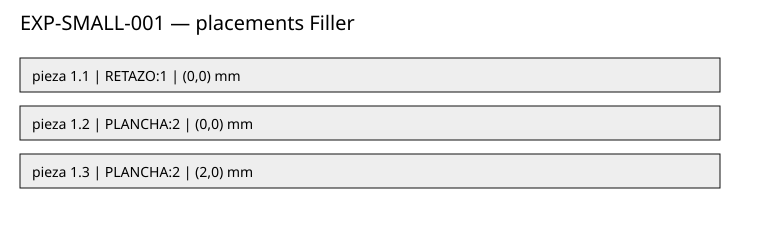

In [11]:
def placement_svg(result, title):  # Definimos un generador SVG pequeño sin dependencias gráficas externas.
    rows = [f'<svg xmlns="http://www.w3.org/2000/svg" width="760" height="{100 + 48 * len(result.placements)}" viewBox="0 0 760 {100 + 48 * len(result.placements)}">']  # Iniciamos el lienzo blanco.
    rows.append('<rect width="100%" height="100%" fill="white"/>')  # Garantizamos fondo blanco.
    rows.append(f'<text x="20" y="30" font-family="sans-serif" font-size="20">{title}</text>')  # Añadimos el título descriptivo.
    for index, placement in enumerate(result.placements):  # Dibujamos una fila por pieza realmente colocada.
        y = 58 + index * 48  # Separamos visualmente las filas.
        label = f"pieza {placement.piece.piece_id}.{placement.piece.unit_index} | {placement.stock.source.value}:{placement.stock.material_id} | ({placement.x_mm},{placement.y_mm}) mm"  # Resumimos la identidad y coordenadas.
        rows.append(f'<rect x="20" y="{y}" width="700" height="34" fill="#eeeeee" stroke="#111111"/>')  # Trazamos una barra monocroma por placement.
        rows.append(f'<text x="32" y="{y + 23}" font-family="sans-serif" font-size="14">{label}</text>')  # Etiquetamos el placement.
    rows.append('</svg>')  # Cerramos el SVG.
    return "".join(rows)  # Devolvemos el gráfico como imagen vectorial.
small_svg = placement_svg(small_filler, "EXP-SMALL-001 — placements Filler")  # Generamos la figura del caso pequeño.
print(small_svg)  # El notebook guarda esta salida como SVG embebido.

### Interpretación de la salida

El gráfico representa el orden y stock de cada placement; no sustituye el detalle geométrico exacto del raster.

## Celda 18. Ejecutar FF SMALL

### Qué hace esta celda

Ejecuta First Fit sobre una reconstrucción nueva de SMALL.

### Por qué la necesitamos

Cada método recibe snapshots nuevos para evitar compartir layouts.

### Qué deberíamos observar

Se miden corrida y métricas oficiales en serie.

In [12]:
from time import perf_counter  # Importamos un reloj monotónico para medir duración local.
from app.modules.optimization.domain.first_fit import FirstFitOptimizer  # Reutilizamos FF productivo sin modificarlo.
from app.modules.optimization.domain.metrics import calculate_metrics  # Reutilizamos el cálculo oficial de métricas.
from decimal import Decimal  # Usamos Decimal para los límites explícitos del fixture.
small_ff_problem = load_problem("EXP-SMALL-001")  # Creamos un snapshot independiente para FF.
small_start = perf_counter()  # Iniciamos el cronómetro antes de optimizar.
small_ff = FirstFitOptimizer().optimize(small_ff_problem)  # Ejecutamos la implementación productiva FF.
small_ff, _ = calculate_metrics(small_ff, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))  # Calculamos métricas oficiales.
small_ff_ms = (perf_counter() - small_start) * 1000  # Convertimos la duración a milisegundos.
print("FF SMALL:", small_ff.placed_units, "/", small_ff.total_units, "unidades; ms:", round(small_ff_ms, 3))  # Mostramos avance y tiempo.

FF SMALL: 3 / 3 unidades; ms: 17.622


### Interpretación de la salida

FF coloca las tres unidades de SMALL; el tiempo se mide en esta sesión y puede variar entre equipos.

## Celda 19. Ejecutar BF SMALL

### Qué hace esta celda

Ejecuta Best Fit sobre otro snapshot nuevo.

### Por qué la necesitamos

BF y FF deben compartir preparación geométrica y métricas para que solo difiera la selección.

### Qué deberíamos observar

Se imprimen unidades colocadas y uso de fuentes.

In [13]:
from app.modules.optimization.domain.best_fit import BestFitOptimizer  # Importamos el selector BF del motor actual.
small_bf_problem = load_problem("EXP-SMALL-001")  # Preparamos una copia independiente del caso.
small_bf_start = perf_counter()  # Iniciamos la medición de BF.
small_bf = BestFitOptimizer().optimize(small_bf_problem)  # Ejecutamos BF productivo.
small_bf, _ = calculate_metrics(small_bf, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))  # Aplicamos las métricas existentes.
small_bf_ms = (perf_counter() - small_bf_start) * 1000  # Registramos la duración total de optimización y métricas.
print("BF SMALL:", small_bf.placed_units, "/", small_bf.total_units, "unidades; ms:", round(small_bf_ms, 3))  # Mostramos la salida real.

BF SMALL: 3 / 3 unidades; ms: 19.421


### Interpretación de la salida

BF produce la misma cobertura en SMALL; el indicador de fuentes se compara en la tabla siguiente.

## Celda 20. Ejecutar WF SMALL

### Qué hace esta celda

Ejecuta Worst Fit en una reconstrucción separada.

### Por qué la necesitamos

WF cambia el selector de stock y mantiene la geometría del motor.

### Qué deberíamos observar

Se informa cantidad colocada y tiempo.

In [14]:
from app.modules.optimization.domain.worst_fit import WorstFitOptimizer  # Importamos el selector WF actual.
small_wf_problem = load_problem("EXP-SMALL-001")  # Construimos un snapshot independiente.
small_wf_start = perf_counter()  # Iniciamos la medición temporal de WF.
small_wf = WorstFitOptimizer().optimize(small_wf_problem)  # Ejecutamos WF sin alterar su implementación.
small_wf, _ = calculate_metrics(small_wf, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))  # Reutilizamos métricas oficiales.
small_wf_ms = (perf_counter() - small_wf_start) * 1000  # Guardamos el tiempo observado.
print("WF SMALL:", small_wf.placed_units, "/", small_wf.total_units, "unidades; ms:", round(small_wf_ms, 3))  # Mostramos cobertura y tiempo.

WF SMALL: 3 / 3 unidades; ms: 17.447


### Interpretación de la salida

WF también completa SMALL; sus decisiones de fuente se ven en los placements.

## Celda 21. Comparar SMALL

### Qué hace esta celda

Resume las cuatro ejecuciones con las métricas comparables.

### Por qué la necesitamos

La tabla evita atribuir diferencias no presentes en los datos.

### Qué deberíamos observar

Los cuatro métodos colocan todas las piezas y consumen una fuente de cada tipo.

In [15]:
def result_row(case_id, method, result, runtime_ms):  # Normalizamos las columnas comparables en una fila.
    metrics = result.metrics  # Obtenemos el objeto de métricas oficial del resultado.
    remnants = sum(stock.source.value == "RETAZO" for stock in result.materials_used)  # Contamos retazos realmente usados.
    sheets = sum(stock.source.value == "PLANCHA" for stock in result.materials_used)  # Contamos planchas realmente usadas.
    return (case_id, method, result.total_units, result.placed_units, result.total_units-result.placed_units, remnants, sheets, str(metrics.utilization_pct) if metrics else "", str(metrics.waste_mm2) if metrics else "", str(metrics.recoverable_remnant_mm2) if metrics else "", round(runtime_ms,3))  # Devolvemos valores de CSV.
small_rows = [result_row("SMALL", "FF", small_ff, small_ff_ms), result_row("SMALL", "BF", small_bf, small_bf_ms), result_row("SMALL", "WF", small_wf, small_wf_ms), result_row("SMALL", "Filler", small_filler, small_filler.computation_time_ms or 0)]  # Consolidamos métodos.
print("case method requested placed unplaced remnants sheets utilization_pct waste recoverable_area runtime_ms")  # Imprimimos encabezados.
for row in small_rows:  # Recorremos filas SMALL en orden fijo.
    print(*row)  # Imprimimos cada fila tabular.

case method requested placed unplaced remnants sheets utilization_pct waste recoverable_area runtime_ms
SMALL FF 3 3 0 1 1 60.000 0.00 8 17.622
SMALL BF 3 3 0 1 1 60.000 0.00 8 19.421
SMALL WF 3 3 0 1 1 60.000 0.00 8 17.447
SMALL Filler 3 3 0 1 1 60.000 0.00 8 18


### Interpretación de la salida

SMALL coincide en cobertura, fuentes y aprovechamiento; la homogeneidad explica por qué no separa las políticas.

## Celda 22. Ejecutar Filler MEDIUM

### Qué hace esta celda

Ejecuta Filler con el límite de residuo del fixture MEDIUM.

### Por qué la necesitamos

Esta corrida muestra si la búsqueda entre pendientes altera el uso de fuentes.

### Qué deberíamos observar

La traza permite contar skips y éxitos posteriores.

In [16]:
medium_filler_problem = load_problem("EXP-MEDIUM-001")  # Preparamos una copia nueva de MEDIUM.
medium_filler, medium_trace = FillerExperimental().optimize(medium_filler_problem, minimum_width_mm=Decimal(str(medium_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=Decimal(str(medium_data["residual_limits"]["minimum_height_mm"])))  # Medimos Filler con la misma regla de residuo.
print("unidades:", medium_filler.placed_units, "/", medium_filler.total_units)  # Mostramos cobertura.
print("fuentes:", medium_trace.pieces_per_source)  # Mostramos unidades colocadas por fuente.
print("skips:", medium_trace.skipped_piece_attempts, "éxitos tras skip:", medium_trace.successful_fill_after_skip)  # Mostramos diagnósticos de Filler.

unidades: 9 / 9
fuentes: {'RETAZO:1:1': 3, 'RETAZO:2:1': 2, 'PLANCHA:3:1': 4}
skips: 11 éxitos tras skip: 1


### Interpretación de la salida

Filler completa 9 unidades en MEDIUM; sus fuentes y aprovechamiento coinciden con FF aunque la búsqueda puede generar intentos adicionales.

## Celda 23. Ejecutar FF/BF/WF MEDIUM

### Qué hace esta celda

Corre los tres baselines secuencialmente sobre copias independientes.

### Por qué la necesitamos

La ejecución seriada limita el uso de memoria y facilita comparar datos homogéneos.

### Qué deberíamos observar

Se ejecutan FF, BF y WF en ese orden, liberando objetos después de cada uno.

In [17]:
import gc  # Importamos el recolector explícito para soltar referencias entre corridas.
medium_results = {}  # Creamos el diccionario de resultados compactos.
for method_name, optimizer_class in [("FF", FirstFitOptimizer), ("BF", BestFitOptimizer), ("WF", WorstFitOptimizer)]:  # Fijamos orden secuencial de baselines.
    case = read_case("EXP-MEDIUM-001")  # Leemos límites oficiales sin modificar el fixture.
    problem = load_problem("EXP-MEDIUM-001")  # Construimos una entrada independiente por método.
    started = perf_counter()  # Iniciamos la medición de la corrida.
    result = optimizer_class().optimize(problem)  # Ejecutamos un baseline y esperamos a que termine.
    result, _ = calculate_metrics(result, Decimal(str(case["residual_limits"]["minimum_width_mm"])), Decimal(str(case["residual_limits"]["minimum_height_mm"])))  # Reutilizamos las métricas oficiales.
    medium_results[method_name] = (result, (perf_counter()-started)*1000)  # Conservamos solo resultado y tiempo.
    print(method_name, result.placed_units, "/", result.total_units, "utilización", result.metrics.utilization_pct)  # Informamos resultado observado.
    del problem, result  # Liberamos referencias a geometría raster pesada.
    gc.collect()  # Solicitamos recolección antes del siguiente baseline.

FF 9 / 9 utilización 28.413
BF 9 / 9 utilización 28.413
WF 9 / 9 utilización 18.584


### Interpretación de la salida

Los tres métodos completan MEDIUM; WF usa dos planchas, mientras FF y BF usan una.

## Celda 24. Comparar MEDIUM

### Qué hace esta celda

Consolida los datos de las cuatro corridas MEDIUM.

### Por qué la necesitamos

Las diferencias deben leerse en cobertura, fuentes, utilización, merma y tiempo.

### Qué deberíamos observar

Filler coincide con FF en el conteo de fuentes y aprovechamiento; BF reduce merma 8 mm²; WF usa una plancha adicional.

In [18]:
medium_rows = [result_row("MEDIUM", name, result, duration) for name, (result, duration) in medium_results.items()]  # Convertimos baselines a filas comparables.
medium_rows.append(result_row("MEDIUM", "Filler", medium_filler, medium_filler.computation_time_ms or 0))  # Agregamos Filler.
for row in medium_rows:  # Recorremos las filas del caso.
    print(*row)  # Mostramos cada método y métrica en el mismo orden.

MEDIUM FF 9 9 0 2 1 28.413 201.86 58 32.199
MEDIUM BF 9 9 0 2 1 28.413 193.86 66 43.185
MEDIUM WF 9 9 0 2 2 18.584 301.86 150 32.337
MEDIUM Filler 9 9 0 2 1 28.413 201.86 58 31


### Interpretación de la salida

Filler y FF usan 2 retazos y 1 plancha con 28.413% de aprovechamiento. BF conserva las fuentes pero registra menos merma recuperable. WF utiliza dos planchas y baja a 18.584%.

## Celda 25. Ejecutar Filler COMPLEX

### Qué hace esta celda

Ejecuta Filler sobre todos los grupos de material y espesor.

### Por qué la necesitamos

El caso amplio prueba rotación, formas y separación por compatibilidad.

### Qué deberíamos observar

Se imprimen cobertura, fuentes activas y switches.

In [19]:
complex_filler_problem = load_problem("EXP-COMPLEX-001")  # Reconstruimos COMPLEX sin compartir objetos con otras corridas.
complex_filler, complex_trace = FillerExperimental().optimize(complex_filler_problem, minimum_width_mm=Decimal(str(complex_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=Decimal(str(complex_data["residual_limits"]["minimum_height_mm"])))  # Corremos Filler con métricas oficiales.
print("unidades:", complex_filler.placed_units, "/", complex_filler.total_units)  # Informamos unidades colocadas.
print("por fuente:", complex_trace.pieces_per_source)  # Mostramos unidades asignadas a cada fuente física.
print("switches:", complex_trace.source_switches, "skips:", complex_trace.skipped_piece_attempts)  # Mostramos decisiones de progresión.

unidades: 24 / 24
por fuente: {'RETAZO:1:1': 2, 'RETAZO:2:1': 2, 'PLANCHA:3:1': 9, 'PLANCHA:3:2': 6, 'RETAZO:4:1': 1, 'PLANCHA:5:1': 4}
switches: 4 skips: 49


### Interpretación de la salida

Filler coloca las 24 unidades de COMPLEX; mantiene 3 retazos y 3 planchas.

## Celda 26. Ejecutar FF/BF/WF COMPLEX

### Qué hace esta celda

Ejecuta baselines secuencialmente con snapshots nuevos.

### Por qué la necesitamos

El orden reduce picos de memoria y hace comparables los tiempos locales.

### Qué deberíamos observar

FF, BF y WF terminan antes de conservar solo resultados métricos.

In [20]:
complex_results = {}  # Creamos un contenedor de resultados para los baselines.
for method_name, optimizer_class in [("FF", FirstFitOptimizer), ("BF", BestFitOptimizer), ("WF", WorstFitOptimizer)]:  # Recorremos métodos uno a uno.
    case = read_case("EXP-COMPLEX-001")  # Leemos límites de residuo del fixture congelado.
    problem = load_problem("EXP-COMPLEX-001")  # Creamos snapshots independientes.
    started = perf_counter()  # Iniciamos la medición total.
    result = optimizer_class().optimize(problem)  # Ejecutamos el método actual.
    result, _ = calculate_metrics(result, Decimal(str(case["residual_limits"]["minimum_width_mm"])), Decimal(str(case["residual_limits"]["minimum_height_mm"])))  # Calculamos métricas comunes.
    complex_results[method_name] = (result, (perf_counter()-started)*1000)  # Retenemos el resultado para la tabla.
    print(method_name, result.placed_units, "/", result.total_units, "planchas", sum(s.source.value == "PLANCHA" for s in result.materials_used))  # Mostramos unidades y planchas.
    del problem, result  # Soltamos referencias a la corrida concluida.
    gc.collect()  # Liberamos basura antes del siguiente método.

FF 24 / 24 planchas 3
BF 24 / 24 planchas 3
WF 24 / 24 planchas 4


### Interpretación de la salida

FF y BF usan 3 planchas; WF abre una cuarta para completar el mismo pedido.

## Celda 27. Comparar COMPLEX

### Qué hace esta celda

Consolida Filler y los tres baselines del caso complejo.

### Por qué la necesitamos

El resultado muestra si la política cambia la solución o solo su camino.

### Qué deberíamos observar

FF, BF y Filler comparten 29.598% de utilización; WF usa una plancha adicional y queda en 25.309%.

In [21]:
complex_rows = [result_row("COMPLEX", name, result, duration) for name, (result, duration) in complex_results.items()]  # Creamos filas de los baselines.
complex_rows.append(result_row("COMPLEX", "Filler", complex_filler, complex_filler.computation_time_ms or 0))  # Añadimos la fila experimental.
for row in complex_rows:  # Recorremos las cuatro observaciones.
    print(*row)  # Presentamos los valores comparables.

COMPLEX FF 24 24 0 3 3 29.598 746.72 184 165.148
COMPLEX BF 24 24 0 3 3 29.598 746.72 184 151.328
COMPLEX WF 24 24 0 3 4 25.309 886.72 268 152.534
COMPLEX Filler 24 24 0 3 3 29.598 746.72 184 186


### Interpretación de la salida

Las 24 unidades caben en todos los métodos. El fixture no evidencia ventaja de Filler sobre FF/BF en aprovechamiento o fuentes.

## Celda 28. Determinismo SMALL ×3

### Qué hace esta celda

Ejecuta tres veces Filler y compara placements y decisiones.

### Por qué la necesitamos

El orden no aleatorio y los desempates estables deben repetir la salida.

### Qué deberíamos observar

Se esperan tres firmas idénticas.

In [22]:
def filler_signature(case_id):  # Creamos una firma estable sin incluir tiempo variable.
    problem = load_problem(case_id)  # Reconstruimos el problema para aislar cada repetición.
    result, trace = FillerExperimental().optimize(problem)  # Ejecutamos Filler con los límites por defecto del caso.
    signature = (tuple((p.piece.identity, p.stock.identity, p.x_mm, p.y_mm, p.rotation_deg) for p in result.placements), trace.processing_order, trace.source_switches, trace.skipped_piece_attempts)  # Recogemos decisiones reproducibles.
    return signature  # Devolvemos la firma de la corrida.
small_signatures = [filler_signature("EXP-SMALL-001") for _ in range(3)]  # Realizamos tres corridas independientes.
print("PASS" if small_signatures[0] == small_signatures[1] == small_signatures[2] else "FAIL")  # Comparamos las tres firmas.

PASS


### Interpretación de la salida

Las tres firmas SMALL son iguales, por lo que el caso pasa el control determinista.

## Celda 29. Determinismo MEDIUM ×3

### Qué hace esta celda

Repite la firma Filler tres veces para MEDIUM.

### Por qué la necesitamos

El caso heterogéneo prueba más desempates que SMALL.

### Qué deberíamos observar

PASS indica placements y decisiones idénticos.

In [23]:
medium_signatures = [filler_signature("EXP-MEDIUM-001") for _ in range(3)]  # Repetimos el caso MEDIUM sin conservar layouts previos.
print("PASS" if medium_signatures[0] == medium_signatures[1] == medium_signatures[2] else "FAIL")  # Verificamos igualdad de la firma completa.

PASS


### Interpretación de la salida

Las tres ejecuciones MEDIUM repiten placements y decisiones; el tiempo no forma parte de la firma.

## Celda 30. Determinismo COMPLEX ×3

### Qué hace esta celda

Repite la misma verificación para COMPLEX.

### Por qué la necesitamos

La carga mayor prueba consistencia de agrupación y orden estable.

### Qué deberíamos observar

Se informará PASS o FAIL a partir de las tres firmas reales.

In [24]:
complex_signatures = [filler_signature("EXP-COMPLEX-001") for _ in range(3)]  # Ejecutamos tres corridas COMPLEX en secuencia.
print("PASS" if complex_signatures[0] == complex_signatures[1] == complex_signatures[2] else "FAIL")  # Comprobamos orden, fuente y coordenadas idénticas.

PASS


### Interpretación de la salida

Las firmas COMPLEX son iguales; el resultado determinista es PASS.

## Celda 31. Tabla consolidada

### Qué hace esta celda

Lee el CSV crudo y presenta todas las comparaciones.

### Por qué la necesitamos

El archivo CSV es la fuente verificable de los números del reporte.

### Qué deberíamos observar

Cada fixture tiene cuatro filas; runtime varía con el equipo.

In [25]:
import csv  # Importamos el lector estándar para consumir el archivo crudo generado.
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_filler_descartado_results.csv"  # Construimos la ubicación de evidencia preservada.
with csv_path.open(encoding="utf-8", newline="") as stream:  # Abrimos el CSV con el encoding definido.
    consolidated = list(csv.DictReader(stream))  # Leemos todas las filas con sus nombres de columna.
for row in consolidated:  # Recorremos los doce resultados medidos.
    print(row["case"], row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])  # Mostramos métricas esenciales.

EXP-SMALL-001 FF 3 1 1 60.000 0.00 11.005
EXP-SMALL-001 BF 3 1 1 60.000 0.00 10.625
EXP-SMALL-001 WF 3 1 1 60.000 0.00 10.554
EXP-SMALL-001 Filler 3 1 1 60.000 0.00 10.581
EXP-MEDIUM-001 FF 9 2 1 28.413 201.86 20.021
EXP-MEDIUM-001 BF 9 2 1 28.413 193.86 25.160
EXP-MEDIUM-001 WF 9 2 2 18.584 301.86 18.221
EXP-MEDIUM-001 Filler 9 2 1 28.413 201.86 21.335
EXP-COMPLEX-001 FF 24 3 3 29.598 746.72 89.855
EXP-COMPLEX-001 BF 24 3 3 29.598 746.72 92.320
EXP-COMPLEX-001 WF 24 3 4 25.309 886.72 87.516
EXP-COMPLEX-001 Filler 24 3 3 29.598 746.72 99.183


### Interpretación de la salida

Se verifican 12 filas: tres fixtures por cuatro métodos. Los tiempos están registrados como decimales en milisegundos.

## Celda 32. Gráfico de aprovechamiento

### Qué hace esta celda

Genera un gráfico de barras SVG con el porcentaje por fixture y método.

### Por qué la necesitamos

La visualización facilita detectar diferencias sin declarar ganador global.

### Qué deberíamos observar

SMALL es igual en todos; WF queda por debajo en MEDIUM y COMPLEX.

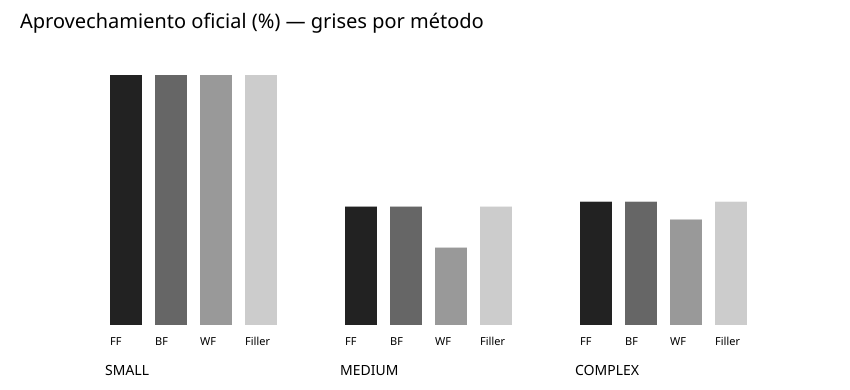

In [26]:
def bar_chart(rows, metric, title):  # Construimos un SVG de barras usando solo texto y formas vectoriales.
    width, height = 850, 390  # Definimos tamaño fijo para que el gráfico sea legible en Colab.
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="white"/>']  # Iniciamos el lienzo blanco.
    parts.append(f'<text x="20" y="28" font-family="sans-serif" font-size="20">{title}</text>')  # Rotulamos el indicador.
    methods = ["FF", "BF", "WF", "Filler"]  # Fijamos el orden de leyenda.
    shades = ["#222222", "#666666", "#999999", "#cccccc"]  # Usamos únicamente grises.
    maximum = max(float(row[metric]) for row in rows)  # Usamos una escala común para comparar los tres fixtures.
    for group_index, case in enumerate(CASES):  # Creamos un grupo por fixture.
        values = [float(next(row[metric] for row in rows if row["case"] == case and row["method"] == method)) for method in methods]  # Buscamos valor real de cada método.
        for method_index, value in enumerate(values):  # Dibujamos una barra por método.
            x = 110 + group_index * 235 + method_index * 45  # Calculamos la posición horizontal.
            bar_height = value * (250 / maximum) if maximum else 0  # Escalamos todas las barras con el mismo máximo global.
            parts.append(f'<rect x="{x}" y="{325-bar_height:.1f}" width="32" height="{bar_height:.1f}" fill="{shades[method_index]}"/>')  # Dibujamos barra gris.
            parts.append(f'<text x="{x}" y="345" font-family="sans-serif" font-size="11">{methods[method_index]}</text>')  # Añadimos etiqueta del método.
        parts.append(f'<text x="{105+group_index*235}" y="375" font-family="sans-serif" font-size="14">{case.replace("EXP-", "").replace("-001", "")}</text>')  # Rotulamos fixture.
    parts.append('</svg>')  # Cerramos el documento SVG.
    return "".join(parts)  # Devolvemos el vector listo para guardar en la salida.
utilization_svg = bar_chart(consolidated, "utilization_pct", "Aprovechamiento oficial (%) — grises por método")  # Graficamos la métrica oficial.
print(utilization_svg)  # El generador del notebook guarda SVG como salida renderizable.

### Interpretación de la salida

Los datos muestran igualdad de FF/BF/Filler en COMPLEX; MEDIUM diferencia merma, pero no utilización entre esos tres métodos.

## Celda 33. Gráfico de fuentes utilizadas

### Qué hace esta celda

Grafica planchas utilizadas por método en cada fixture.

### Por qué la necesitamos

El número de planchas nuevas tiene impacto operativo separado del porcentaje.

### Qué deberíamos observar

WF utiliza más planchas en MEDIUM y COMPLEX.

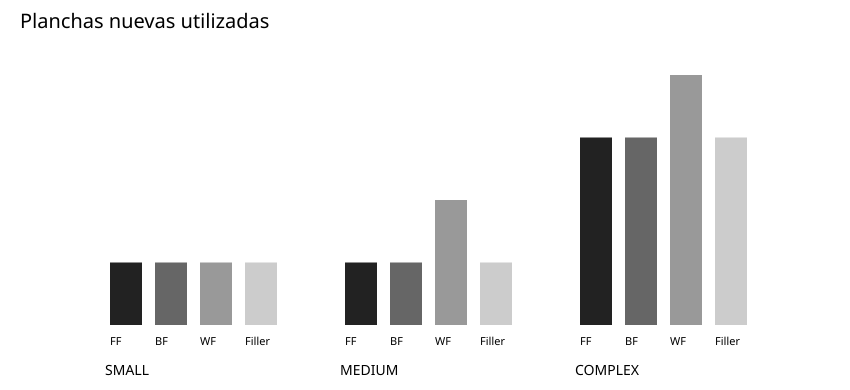

In [27]:
def stock_chart(rows):  # Creamos otro SVG de barras con los conteos de planchas.
    return bar_chart(rows, "sheets_used", "Planchas nuevas utilizadas")  # Reutilizamos el mismo motor vectorial monocromo.
sheets_svg = stock_chart(consolidated)  # Generamos el gráfico de stock de planchas.
print(sheets_svg)  # Embebemos el vector como salida ejecutada.

### Interpretación de la salida

WF requiere dos planchas en MEDIUM frente a una y cuatro en COMPLEX frente a tres para FF, BF y Filler.

## Celda 34. Gráfico de tiempo

### Qué hace esta celda

Grafica los tiempos registrados en milisegundos.

### Por qué la necesitamos

El costo computacional es una métrica de comparación, pero estas duraciones pequeñas son sensibles al entorno.

### Qué deberíamos observar

Filler consume más tiempo en COMPLEX por las búsquedas repetidas de pendientes.

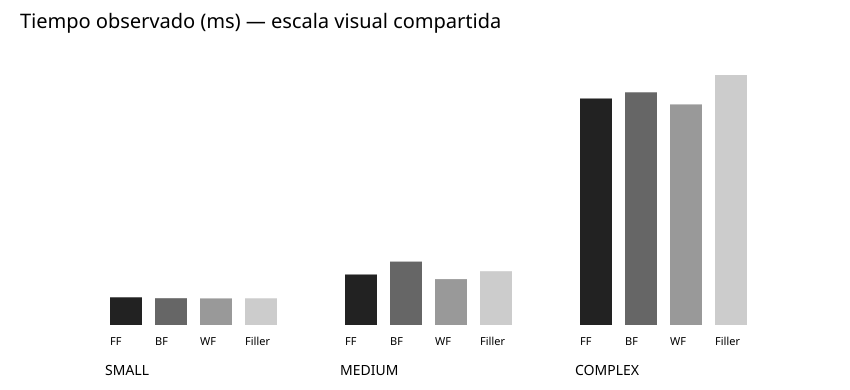

In [28]:
runtime_svg = bar_chart(consolidated, "runtime_ms", "Tiempo observado (ms) — escala visual compartida")  # Construimos el gráfico con tiempos CSV.
print(runtime_svg)  # Guardamos el SVG como salida del notebook ejecutado.

### Interpretación de la salida

En la corrida registrada Filler tarda cerca de 21 ms en MEDIUM y 99 ms en COMPLEX; compare valores solo en el mismo entorno.

## Celda 35. Comportamiento específico Filler

### Qué hace esta celda

Resume skips, éxitos posteriores, fuentes y orden en COMPLEX.

### Por qué la necesitamos

Estas métricas explican la decisión y no sustituyen las métricas oficiales.

### Qué deberíamos observar

Las listas permiten ubicar dónde una pieza posterior llenó la fuente activa.

In [29]:
for attempt in complex_trace.attempts:  # Recorremos todos los intentos de Filler del último caso.
    if attempt["decision"] == "skip_temporarily" or attempt["fits"]:  # Filtramos rechazos temporales y colocaciones.
        print(attempt["piece_id"], attempt["area_mm2"], attempt["source"], attempt["material_id"], attempt["decision"], attempt["rotation_deg"], attempt["x_mm"], attempt["y_mm"])  # Mostramos detalle de decisión.
print("orden efectivo:", complex_trace.processing_order)  # Reportamos el orden que terminó colocándose.
print("unidades por fuente:", complex_trace.pieces_per_source)  # Resumimos cuántas unidades entraron en cada objeto.
print("cambios:", complex_trace.source_switches, "saltos:", complex_trace.skipped_piece_attempts, "rellenos tras skip:", complex_trace.successful_fill_after_skip)  # Cerramos con diagnósticos.

1 27.00 RETAZO 1 place 0 1 1
1 27.00 RETAZO 1 place 0 1 5
1 27.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 2 place 55 1 1
1 27.00 RETAZO 2 skip_temporarily None None None
1 27.00 RETAZO 2 skip_temporar

### Interpretación de la salida

La traza completa está guardada en JSON; aquí se muestran intentos que explican el avance de la fuente activa.

## Celda 36. Observaciones experimentales

### Qué hace esta celda

Resume lo que muestran las métricas medidas sin llamar ganador a ningún método.

### Por qué la necesitamos

El objetivo es entender diferencias, reglas y limitaciones para Andro.

### Qué deberíamos observar

Todos completan los tres fixtures; Filler coincide con FF en fuentes y utilización para estos casos.

In [30]:
for case in CASES:  # Recorremos los tres experimentos en su orden oficial.
    rows = [row for row in consolidated if row["case"] == case]  # Filtramos los cuatro métodos para el caso.
    placed = {row["placed_units"] for row in rows}  # Comprobamos si la cobertura difiere.
    utilization = {row["method"]: row["utilization_pct"] for row in rows}  # Preparamos aprovechamientos medidos.
    print(case, "cobertura única:", len(placed) == 1, "aprovechamiento:", utilization)  # Resumimos cobertura y eficiencia.
print("Observación: Filler fue determinista en las tres repeticiones de cada fixture.")  # Registramos el control determinista observado.
print("Limitación: solo hay tres fixtures congelados y el tiempo local no se extrapola a producción.")  # Declaramos el alcance del resultado.

EXP-SMALL-001 cobertura única: True aprovechamiento: {'FF': '60.000', 'BF': '60.000', 'WF': '60.000', 'Filler': '60.000'}
EXP-MEDIUM-001 cobertura única: True aprovechamiento: {'FF': '28.413', 'BF': '28.413', 'WF': '18.584', 'Filler': '28.413'}
EXP-COMPLEX-001 cobertura única: True aprovechamiento: {'FF': '29.598', 'BF': '29.598', 'WF': '25.309', 'Filler': '29.598'}
Observación: Filler fue determinista en las tres repeticiones de cada fixture.
Limitación: solo hay tres fixtures congelados y el tiempo local no se extrapola a producción.


### Interpretación de la salida

Los datos no sostienen una mejora general de Filler. Filler es distinto por política y por sus intentos, pero coincide con FF en estos fixtures; WF consume más planchas en MEDIUM y COMPLEX. El resultado debe validarse de nuevo en Colab.